# Round 1 — Data Understanding, Preparation & EDA

**Challenge:** Certificate Issuance Monitoring and Delay Analytics

This single notebook contains all **10 mandatory Round 1 questions**. Each question is followed by the code used to answer it. Run the notebook from top to bottom.

> **Important:** The prototype dataset is synthetic/domain-grounded data. The statistics produced here describe the prototype dataset, not official Tamil Nadu government statistics.

## Setup — Imports, paths and helper functions

In [3]:
# ============================================================
# SETUP — ROUND 1 NOTEBOOK
# ============================================================

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pointbiserialr, mannwhitneyu, chi2_contingency
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------
# DISPLAY SETTINGS
# ------------------------------------------------------------

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

# ------------------------------------------------------------
# PROJECT PATH
# ------------------------------------------------------------

PROJECT_ROOT = Path(r"D:\Datascience Hackathon")

PROJECT_FOLDER = PROJECT_ROOT / "certificate-delay-intelligence"

DATA_FOLDER = PROJECT_ROOT / "dataset"

OUTPUT_FOLDER = PROJECT_FOLDER / "outputs"

OUTPUT_DIR = OUTPUT_FOLDER / "round1_notebook"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DATASET PATHS
# ------------------------------------------------------------

DATA_CANDIDATES = [
    DATA_FOLDER / "certificate_applications_raw_50000.csv",
    DATA_FOLDER / "certificate_applications_raw_50000.CSV",

    PROJECT_ROOT / "certificate_applications_raw_50000.csv",

    PROJECT_FOLDER / "dataset" / "certificate_applications_raw_50000.csv",

    DATA_FOLDER / "train.csv",
    PROJECT_ROOT / "Dataset" / "train.csv",
]

# ------------------------------------------------------------
# FIND DATASET
# ------------------------------------------------------------

DATA_PATH = None

for path in DATA_CANDIDATES:
    if path.exists() and path.is_file():
        DATA_PATH = path
        break

# ------------------------------------------------------------
# IF NOT FOUND — SHOW AVAILABLE CSV FILES
# ------------------------------------------------------------

if DATA_PATH is None:

    print("=" * 80)
    print("DATASET NOT FOUND")
    print("=" * 80)

    print("\nExpected project location:")
    print(DATA_FOLDER)

    print("\nSearching for CSV files inside the project folder...")

    csv_files = list(PROJECT_ROOT.rglob("*.csv"))

    if csv_files:

        print("\nCSV files found:")

        for file in csv_files:
            print("  ", file)

        print(
            "\nPlease change DATA_PATH manually to the correct CSV shown above."
        )

    else:

        print("\nNo CSV files were found inside:")
        print(PROJECT_ROOT)

    raise FileNotFoundError(
        "\nDataset CSV could not be located. "
        "Check the printed paths above."
    )

# ------------------------------------------------------------
# SUCCESS MESSAGE
# ------------------------------------------------------------

print("=" * 80)
print("ROUND 1 NOTEBOOK SETUP")
print("=" * 80)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nProject folder:")
print(PROJECT_FOLDER)

print("\nDataset:")
print(DATA_PATH)

print("\nOutput folder:")
print(OUTPUT_DIR)

print("\nDataset exists:")
print(DATA_PATH.exists())

print("\nSetup completed successfully.")

ROUND 1 NOTEBOOK SETUP

Project root:
D:\Datascience Hackathon

Project folder:
D:\Datascience Hackathon\certificate-delay-intelligence

Dataset:
D:\Datascience Hackathon\dataset\certificate_applications_raw_50000.csv

Output folder:
D:\Datascience Hackathon\certificate-delay-intelligence\outputs\round1_notebook

Dataset exists:
True

Setup completed successfully.


# Question 1

## Understand the challenge objective and identify the prediction target.

In [4]:

print("=" * 80)
print("QUESTION 1 — CHALLENGE OBJECTIVE AND PREDICTION TARGET")
print("=" * 80)

print("""
Challenge objective:
Predict whether a certificate application is likely to miss its target TAT,
estimate the remaining turnaround time, identify the bottleneck stage,
and explain operational factors associated with delay risk.

Primary classification target:
missed_target = 1 when actual_total_tat_days > target_tat_days; otherwise 0.

Primary regression target:
actual_remaining_tat_days = remaining turnaround time from the current snapshot.

Bottleneck analysis target:
actual_bottleneck_stage = stage consuming the largest actual processing time.

Important:
Actual outcome columns will not be used as input features in the final model.
""")


QUESTION 1 — CHALLENGE OBJECTIVE AND PREDICTION TARGET

Challenge objective:
Predict whether a certificate application is likely to miss its target TAT,
estimate the remaining turnaround time, identify the bottleneck stage,
and explain operational factors associated with delay risk.

Primary classification target:
missed_target = 1 when actual_total_tat_days > target_tat_days; otherwise 0.

Primary regression target:
actual_remaining_tat_days = remaining turnaround time from the current snapshot.

Bottleneck analysis target:
actual_bottleneck_stage = stage consuming the largest actual processing time.

Important:
Actual outcome columns will not be used as input features in the final model.



# Question 2

## Import and inspect the supplied dataset.

In [5]:

df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print("=" * 80)
print("QUESTION 2 — DATASET IMPORT AND INSPECTION")
print("=" * 80)
print("Rows    :", df_raw.shape[0])
print("Columns :", df_raw.shape[1])

print("\nFirst 5 rows:")
display(df_raw.head())

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nBasic info:")
df_raw.info()


QUESTION 2 — DATASET IMPORT AND INSPECTION
Rows    : 50000
Columns : 39

First 5 rows:


,application_id,service_code,certificate_type,district,taluk,submission_channel,submission_date,submission_month,submission_day_of_week,peak_period_flag,current_stage,application_age_days,stage_age_days,days_to_target,target_tat_days,required_document_count,submitted_document_count,document_completeness_pct,missing_document_count,verification_complexity,resubmission_count,queue_length,pending_cases_department,department_workload_index,staff_availability_pct,recent_backlog_growth_pct,historical_stage_median_days,historical_service_median_days,actual_initial_scrutiny_days,actual_document_verification_days,actual_department_review_days,actual_approval_days,actual_certificate_issuance_days,actual_total_tat_days,actual_remaining_tat_days,missed_target,delay_overrun_days,actual_bottleneck_stage,target_tat_basis
0,APP-1622-020496,REV-102,Nativity Certificate,Virudhunagar,Virudhunagar-T03,e-Sevai Centre,2024-05-13,5,Monday,1,Department Review,3.21,1.02,3.79,7,5.0,4.0,80.00,1.0,3.0,0.0,61,78.0,47.08,62.63,3.14,1.53,6.18,0.54,1.64,2.52,1.80,0.28,6.79,3.59,0,0.00,Department Review,Official TNeGA listed service time: 07 days
1,APP-1622-046294,REV-109,Widow Certificate,Tiruvannamalai,Tiruvannamalai-T01,Online Citizen Portal,2025-02-01,2,Saturday,0,Document Verification,2.49,1.31,12.51,15,6.0,5.0,83.33,1.0,3.2,0.0,27,45.0,25.96,79.63,-1.91,2.18,11.50,1.18,2.62,4.87,2.39,0.45,11.51,9.02,0,0.00,Department Review,Prototype assumption - TNeGA currently shows '...
2,APP-1622-020461,REV-120,Unmarried Certificate,Perambalur,Perambalur-T02,e-Sevai Centre,2024-08-29,8,Thursday,1,department review,4.95,0.87,10.05,15,5.0,5.0,100.00,0.0,2.5,0.0,51,68.0,39.76,87.89,12.4,3.38,11.92,1.25,2.83,4.55,3.49,0.41,12.53,7.58,0,0.00,Department Review,Official TNeGA listed service time: 15 days
3,APP-1622-006848,REV-102,Nativity Certificate,Ramanathapuram,Ramanathapuram-T04,Online Citizen Portal,2024-10-31,10,Thursday,0,Department Review,3.79,0.97,3.21,7,5.0,3.0,60.00,2.0,3.0,2.0,38,40.0,49.29,89.56,2.98,1.47,5.90,0.67,2.15,2.66,1.98,0.19,7.65,3.86,1,0.65,Department Review,Official TNeGA listed service time: 07 days
4,APP-1622-035235,REV-102,Nativity Certificate,Viluppuram,Viluppuram-T04,Online Citizen Portal,2024-07-06,7,Saturday,1,Department Review,3.11,1.28,3.89,7,5.0,4.0,80.00,1.0,3.0,0.0,38,75.0,48.52,79.67,6.19,1.59,6.00,0.60,1.23,3.12,1.21,0.30,6.46,3.35,0,0.00,Department Review,Official TNeGA listed service time: 07 days



Column names:
['application_id', 'service_code', 'certificate_type', 'district', 'taluk', 'submission_channel', 'submission_date', 'submission_month', 'submission_day_of_week', 'peak_period_flag', 'current_stage', 'application_age_days', 'stage_age_days', 'days_to_target', 'target_tat_days', 'required_document_count', 'submitted_document_count', 'document_completeness_pct', 'missing_document_count', 'verification_complexity', 'resubmission_count', 'queue_length', 'pending_cases_department', 'department_workload_index', 'staff_availability_pct', 'recent_backlog_growth_pct', 'historical_stage_median_days', 'historical_service_median_days', 'actual_initial_scrutiny_days', 'actual_document_verification_days', 'actual_department_review_days', 'actual_approval_days', 'actual_certificate_issuance_days', 'actual_total_tat_days', 'actual_remaining_tat_days', 'missed_target', 'delay_overrun_days', 'actual_bottleneck_stage', 'target_tat_basis']

Data types:


,dtype
application_id,object
service_code,object
certificate_type,object
district,object
taluk,object
submission_channel,object
submission_date,object
submission_month,int64
submission_day_of_week,object
peak_period_flag,int64



Basic info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   application_id                     50000 non-null  object 
 1   service_code                       50000 non-null  object 
 2   certificate_type                   50000 non-null  object 
 3   district                           50000 non-null  object 
 4   taluk                              50000 non-null  object 
 5   submission_channel                 50000 non-null  object 
 6   submission_date                    50000 non-null  object 
 7   submission_month                   50000 non-null  int64  
 8   submission_day_of_week             50000 non-null  object 
 9   peak_period_flag                   50000 non-null  int64  
 10  current_stage                      50000 non-null  object 
 11  application_age_days               49499 

# Question 3

## Study the dataset dimensions, attributes, data types and target distribution.

In [6]:

print("=" * 80)
print("QUESTION 3 — DIMENSIONS, ATTRIBUTES, DATA TYPES AND TARGET")
print("=" * 80)

print(f"Dataset dimensions: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")

summary = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "missing": df_raw.isna().sum().values,
    "unique_values": [df_raw[c].nunique(dropna=True) for c in df_raw.columns]
})
display(summary)

if "missed_target" in df_raw.columns:
    target_counts = df_raw["missed_target"].value_counts(dropna=False).sort_index()
    target_summary = pd.DataFrame({
        "count": target_counts,
        "percentage": (target_counts / len(df_raw) * 100).round(2)
    })
    print("\nTarget distribution:")
    display(target_summary)
else:
    print("\nmissed_target is not present. It will be created from actual_total_tat_days > target_tat_days when needed.")


QUESTION 3 — DIMENSIONS, ATTRIBUTES, DATA TYPES AND TARGET
Dataset dimensions: 50000 rows × 39 columns


,column,dtype,missing,unique_values
0,application_id,object,0,49800
1,service_code,object,0,10
2,certificate_type,object,0,20
3,district,object,0,38
4,taluk,object,0,152
5,submission_channel,object,0,4
6,submission_date,object,0,1063
7,submission_month,int64,0,12
8,submission_day_of_week,object,0,7
9,peak_period_flag,int64,0,2



Target distribution:


,count,percentage
missed_target,,
0,36361,72.72
1,13639,27.28


# Question 4

## Handle missing values, duplicate records, inconsistent values and incorrect data types.

In [7]:

print("=" * 80)
print("QUESTION 4 — DATA QUALITY AND CLEANING")
print("=" * 80)

df = df_raw.copy()

# 1. Remove exact duplicate rows only.
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 2. Normalize categorical values.
categorical_cols = [
    "certificate_type", "submission_channel", "current_stage",
    "service_code", "district", "taluk", "submission_day_of_week",
    "target_tat_basis"
]

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip().str.lower()

certificate_map = {
    "community certificate": "community", "community": "community",
    "income certificate": "income", "income": "income",
    "nativity certificate": "nativity", "nativity": "nativity", "domicile": "nativity",
    "legal heir certificate": "legal heir", "legal heir": "legal heir",
    "obc certificate": "obc", "obc": "obc",
    "residence certificate": "residence", "residence": "residence",
    "inter caste marriage certificate": "inter caste marriage",
    "inter caste marriage": "inter caste marriage",
    "unmarried certificate": "unmarried", "unmarried": "unmarried",
    "first graduate certificate": "first graduate", "first graduate": "first graduate",
    "widow certificate": "widow", "widow": "widow"
}
if "certificate_type" in df.columns:
    df["certificate_type"] = df["certificate_type"].replace(certificate_map)

stage_map = {
    "initial scrutiny": "initial scrutiny",
    "initial_review": "initial scrutiny",
    "initial review": "initial scrutiny",
    "document verification": "document verification",
    "document_verification": "document verification",
    "department review": "department review",
    "department_review": "department review",
    "approval": "approval",
    "certificate issuance": "certificate issuance",
    "certificate_issuance": "certificate issuance"
}
if "current_stage" in df.columns:
    df["current_stage"] = df["current_stage"].replace(stage_map)

channel_map = {
    "e-sevai": "e-sevai", "esevai": "e-sevai", "e_sevai": "e-sevai",
    "online": "online"
}
if "submission_channel" in df.columns:
    df["submission_channel"] = df["submission_channel"].replace(channel_map)

# 3. Convert numeric columns safely.
numeric_cols = [
    "application_age_days", "stage_age_days", "days_to_target", "target_tat_days",
    "required_document_count", "submitted_document_count", "document_completeness_pct",
    "missing_document_count", "verification_complexity", "resubmission_count",
    "queue_length", "pending_cases_department", "department_workload_index",
    "staff_availability_pct", "recent_backlog_growth_pct",
    "historical_stage_median_days", "historical_service_median_days",
    "actual_initial_scrutiny_days", "actual_document_verification_days",
    "actual_department_review_days", "actual_approval_days",
    "actual_certificate_issuance_days", "actual_total_tat_days",
    "actual_remaining_tat_days", "missed_target", "delay_overrun_days",
    "peak_period_flag", "submission_month"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Parse the mixed date formats explicitly.
if "submission_date" in df.columns:
    raw_dates = df["submission_date"].astype("string").str.strip()
    parsed_dates = pd.to_datetime(raw_dates, format="%d-%m-%Y", errors="coerce")
    mask = parsed_dates.isna()
    parsed_dates.loc[mask] = pd.to_datetime(
        raw_dates.loc[mask], format="%Y/%m/%d", errors="coerce"
    )
    df["submission_date_parsed"] = parsed_dates

# 5. Range validation.
range_rules = {
    "document_completeness_pct": (0, 100),
    "staff_availability_pct": (0, 100),
    "department_workload_index": (0, 100),
    "verification_complexity": (1, 5),
    "peak_period_flag": (0, 1),
}
for col, (low, high) in range_rules.items():
    if col in df.columns:
        df.loc[~df[col].between(low, high), col] = np.nan

# Non-negative operational/count fields.
nonnegative_cols = [
    "application_age_days", "stage_age_days", "required_document_count",
    "submitted_document_count", "missing_document_count", "resubmission_count",
    "queue_length", "pending_cases_department", "recent_backlog_growth_pct",
    "historical_stage_median_days", "historical_service_median_days"
]
for col in nonnegative_cols:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

# Logical document consistency.
if {"submitted_document_count", "required_document_count"}.issubset(df.columns):
    bad = df["submitted_document_count"] > df["required_document_count"]
    df.loc[bad, ["submitted_document_count", "required_document_count"]] = np.nan

if {"missing_document_count", "required_document_count"}.issubset(df.columns):
    bad = df["missing_document_count"] > df["required_document_count"]
    df.loc[bad, "missing_document_count"] = np.nan

# Create classification target if absent.
if "missed_target" not in df.columns:
    df["missed_target"] = (
        df["actual_total_tat_days"] > df["target_tat_days"]
    ).astype(int)

missing_before = int(df.isna().sum().sum())

# Round-1 imputation: group median first, then global median.
group_cols = [c for c in ["certificate_type", "current_stage"] if c in df.columns]

for col in numeric_cols:
    if col not in df.columns or col in ["missed_target", "peak_period_flag", "submission_month"]:
        continue
    if group_cols:
        group_median = df.groupby(group_cols, dropna=False)[col].transform("median")
        df[col] = df[col].fillna(group_median)
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if col in df.columns and df[col].isna().any():
        mode = df[col].mode(dropna=True)
        if len(mode):
            df[col] = df[col].fillna(mode.iloc[0])

missing_after = int(df.isna().sum().sum())

print("Exact duplicate rows removed :", exact_duplicates)
print("Rows after cleaning           :", len(df))
print("Missing cells before impute   :", missing_before)
print("Missing cells after impute    :", missing_after)
print("Duplicate app IDs             :",
      df["application_id"].duplicated().sum() if "application_id" in df.columns else "N/A")

print("\nNormalized categorical cardinalities:")
for col in categorical_cols:
    if col in df.columns:
        print(f"  {col}: {df[col].nunique(dropna=True)} unique values")

display(df.head())


QUESTION 4 — DATA QUALITY AND CLEANING
Exact duplicate rows removed : 200
Rows after cleaning           : 49800
Missing cells before impute   : 68769
Missing cells after impute    : 49693
Duplicate app IDs             : 0

Normalized categorical cardinalities:
  certificate_type: 10 unique values
  submission_channel: 2 unique values
  current_stage: 3 unique values
  service_code: 10 unique values
  district: 38 unique values
  taluk: 152 unique values
  submission_day_of_week: 7 unique values
  target_tat_basis: 3 unique values


,application_id,service_code,certificate_type,district,taluk,submission_channel,submission_date,submission_month,submission_day_of_week,peak_period_flag,current_stage,application_age_days,stage_age_days,days_to_target,target_tat_days,required_document_count,submitted_document_count,document_completeness_pct,missing_document_count,verification_complexity,resubmission_count,queue_length,pending_cases_department,department_workload_index,staff_availability_pct,recent_backlog_growth_pct,historical_stage_median_days,historical_service_median_days,actual_initial_scrutiny_days,actual_document_verification_days,actual_department_review_days,actual_approval_days,actual_certificate_issuance_days,actual_total_tat_days,actual_remaining_tat_days,missed_target,delay_overrun_days,actual_bottleneck_stage,target_tat_basis,submission_date_parsed
0,APP-1622-020496,rev-102,nativity,virudhunagar,virudhunagar-t03,e-sevai centre,2024-05-13,5,monday,1.0,department review,3.21,1.02,3.79,7,5.0,4.0,80.00,1.0,3.0,0.0,61.0,78.0,47.08,62.63,3.14,1.53,6.18,0.54,1.64,2.52,1.80,0.28,6.79,3.59,0,0.00,Department Review,official tnega listed service time: 07 days,NaT
1,APP-1622-046294,rev-109,widow,tiruvannamalai,tiruvannamalai-t01,online citizen portal,2025-02-01,2,saturday,0.0,document verification,2.49,1.31,12.51,15,6.0,5.0,83.33,1.0,3.2,0.0,27.0,45.0,25.96,79.63,6.79,2.18,11.50,1.18,2.62,4.87,2.39,0.45,11.51,9.02,0,0.00,Department Review,prototype assumption - tnega currently shows '...,NaT
2,APP-1622-020461,rev-120,unmarried,perambalur,perambalur-t02,e-sevai centre,2024-08-29,8,thursday,1.0,department review,4.95,0.87,10.05,15,5.0,5.0,100.00,0.0,2.5,0.0,51.0,68.0,39.76,87.89,12.40,3.38,11.92,1.25,2.83,4.55,3.49,0.41,12.53,7.58,0,0.00,Department Review,official tnega listed service time: 15 days,NaT
3,APP-1622-006848,rev-102,nativity,ramanathapuram,ramanathapuram-t04,online citizen portal,2024-10-31,10,thursday,0.0,department review,3.79,0.97,3.21,7,5.0,3.0,60.00,2.0,3.0,2.0,38.0,40.0,49.29,89.56,2.98,1.47,5.90,0.67,2.15,2.66,1.98,0.19,7.65,3.86,1,0.65,Department Review,official tnega listed service time: 07 days,NaT
4,APP-1622-035235,rev-102,nativity,viluppuram,viluppuram-t04,online citizen portal,2024-07-06,7,saturday,1.0,department review,3.11,1.28,3.89,7,5.0,4.0,80.00,1.0,3.0,0.0,38.0,75.0,48.52,79.67,6.19,1.59,6.00,0.60,1.23,3.12,1.21,0.30,6.46,3.35,0,0.00,Department Review,official tnega listed service time: 07 days,NaT


# Question 5

## Detect and treat noisy values and outliers using an appropriate statistical method.

In [8]:

print("=" * 80)
print("QUESTION 5 — OUTLIER DETECTION USING IQR")
print("=" * 80)

outlier_numeric_cols = [
    "application_age_days", "stage_age_days", "days_to_target", "target_tat_days",
    "required_document_count", "submitted_document_count", "document_completeness_pct",
    "missing_document_count", "verification_complexity", "resubmission_count",
    "queue_length", "pending_cases_department", "department_workload_index",
    "staff_availability_pct", "recent_backlog_growth_pct",
    "historical_stage_median_days", "historical_service_median_days",
    "actual_initial_scrutiny_days", "actual_document_verification_days",
    "actual_department_review_days", "actual_approval_days",
    "actual_certificate_issuance_days", "actual_total_tat_days",
    "actual_remaining_tat_days", "delay_overrun_days"
]

rows = []
for col in outlier_numeric_cols:
    if col not in df.columns:
        continue
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    if s.empty:
        continue

    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())

    rows.append([
        col, q1, q3, iqr, lower, upper, count,
        round(count / len(s) * 100, 2)
    ])

outlier_report = pd.DataFrame(rows, columns=[
    "feature", "Q1", "Q3", "IQR", "lower_bound",
    "upper_bound", "outlier_count", "outlier_pct"
]).sort_values("outlier_count", ascending=False)

display(outlier_report)
outlier_report.to_csv(
    OUTPUT_DIR / "round1_iqr_outlier_report.csv", index=False
)

print("""
Treatment policy:
• IQR is used to statistically detect outliers.
• Genuine operational extremes are retained because they represent the delay phenomenon.
• Invalid domain values are corrected/converted to missing during cleaning.
• Negative days_to_target can be valid because an application may already have crossed its target.
""")


QUESTION 5 — OUTLIER DETECTION USING IQR


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
24,delay_overrun_days,0.00,0.14,0.14,-0.210,0.350,10775,21.64
9,resubmission_count,0.00,0.00,0.00,0.000,0.000,8671,17.41
14,recent_backlog_growth_pct,4.70,9.80,5.10,-2.950,17.450,2009,4.03
7,missing_document_count,0.00,1.00,1.00,-1.500,2.500,1672,3.36
1,stage_age_days,0.70,2.14,1.44,-1.460,4.300,1182,2.37
0,application_age_days,2.27,5.37,3.10,-2.380,10.020,988,1.98
23,actual_remaining_tat_days,4.97,9.43,4.46,-1.720,16.120,882,1.77
19,actual_department_review_days,3.06,5.66,2.60,-0.840,9.560,857,1.72
18,actual_document_verification_days,2.01,3.66,1.65,-0.465,6.135,769,1.54
20,actual_approval_days,1.83,3.29,1.46,-0.360,5.480,634,1.27



Treatment policy:
• IQR is used to statistically detect outliers.
• Genuine operational extremes are retained because they represent the delay phenomenon.
• Invalid domain values are corrected/converted to missing during cleaning.
• Negative days_to_target can be valid because an application may already have crossed its target.



# Question 6

## Encode categorical variables required for model development.

In [9]:

print("=" * 80)
print("QUESTION 6 — CATEGORICAL ENCODING")
print("=" * 80)

categorical_features = [
    "service_code", "certificate_type", "district",
    "target_tat_basis", "current_stage", "submission_day_of_week"
]
categorical_features = [c for c in categorical_features if c in df.columns]

# Round-1 demonstration of One-Hot Encoding.
# In Round 2, the encoder will be fitted on TRAINING DATA ONLY.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

encoded_array = encoder.fit_transform(df[categorical_features])
encoded_feature_names = encoder.get_feature_names_out(categorical_features)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_feature_names,
    index=df.index
)

print("Categorical input columns:")
print(categorical_features)
print("\nOriginal categorical columns:", len(categorical_features))
print("Generated one-hot features  :", len(encoded_feature_names))

print("\nSample encoded data:")
display(encoded_df.head())

encoded_df.to_csv(
    OUTPUT_DIR / "round1_encoded_categorical_features.csv",
    index=False
)

print("\nSaved:", OUTPUT_DIR / "round1_encoded_categorical_features.csv")
print("\nRound 2 note: refit the encoder using training data only for leakage-safe modeling.")


QUESTION 6 — CATEGORICAL ENCODING
Categorical input columns:
['service_code', 'certificate_type', 'district', 'target_tat_basis', 'current_stage', 'submission_day_of_week']

Original categorical columns: 6
Generated one-hot features  : 71

Sample encoded data:


,service_code_rev-101,service_code_rev-102,service_code_rev-103,service_code_rev-104,service_code_rev-109,service_code_rev-113,service_code_rev-114,service_code_rev-115,service_code_rev-116,service_code_rev-120,certificate_type_community,certificate_type_first graduate,certificate_type_income,certificate_type_inter caste marriage,certificate_type_legal heir,certificate_type_nativity,certificate_type_obc,certificate_type_residence,certificate_type_unmarried,certificate_type_widow,district_ariyalur,district_chengalpattu,district_chennai,district_coimbatore,district_cuddalore,district_dharmapuri,district_dindigul,district_erode,district_kallakurichi,district_kancheepuram,district_kanyakumari,district_karur,district_krishnagiri,district_madurai,district_mayiladuthurai,district_nagapattinam,district_namakkal,district_perambalur,district_pudukottai,district_ramanathapuram,district_ranipet,district_salem,district_sivaganga,district_tenkasi,district_thanjavur,district_the nilgiris,district_theni,district_thiruvallur,district_thiruvarur,district_thoothukudi,district_tiruchirappalli,district_tirunelveli,district_tirupathur,district_tiruppur,district_tiruvannamalai,district_vellore,district_viluppuram,district_virudhunagar,target_tat_basis_official tnega listed service time: 07 days,target_tat_basis_official tnega listed service time: 15 days,target_tat_basis_prototype assumption - tnega currently shows '-' for service time,current_stage_department review,current_stage_document verification,current_stage_initial scrutiny,submission_day_of_week_friday,submission_day_of_week_monday,submission_day_of_week_saturday,submission_day_of_week_sunday,submission_day_of_week_thursday,submission_day_of_week_tuesday,submission_day_of_week_wednesday
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0



Saved: D:\Datascience Hackathon\certificate-delay-intelligence\outputs\round1_notebook\round1_encoded_categorical_features.csv

Round 2 note: refit the encoder using training data only for leakage-safe modeling.


# Question 7

## Perform descriptive statistical analysis on the cleaned dataset.

In [10]:

print("=" * 80)
print("QUESTION 7 — DESCRIPTIVE STATISTICS")
print("=" * 80)

numeric_for_stats = df.select_dtypes(include=np.number).columns.tolist()

descriptive_stats = df[numeric_for_stats].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).T

display(descriptive_stats)

if "missed_target" in df.columns:
    target_summary = (
        df["missed_target"]
        .value_counts()
        .sort_index()
        .to_frame("count")
    )
    target_summary["percentage"] = (
        target_summary["count"] / len(df) * 100
    ).round(2)

    print("\nTarget summary:")
    display(target_summary)

if {"certificate_type", "missed_target"}.issubset(df.columns):
    cert_summary = (
        df.groupby("certificate_type")["missed_target"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )
    cert_summary["delay_rate_pct"] = (
        cert_summary["mean"] * 100
    ).round(2)

    print("\nCertificate-level descriptive summary:")
    display(cert_summary[["count", "delay_rate_pct"]])

descriptive_stats.to_csv(
    OUTPUT_DIR / "round1_descriptive_statistics.csv"
)


QUESTION 7 — DESCRIPTIVE STATISTICS


,count,mean,std,min,5%,25%,50%,75%,95%,max
submission_month,49800.0,5.900120,3.409245,1.00,1.0000,3.00,5.000,9.00,12.0000,12.00
peak_period_flag,49800.0,0.464880,0.498770,0.00,0.0000,0.00,0.000,1.00,1.0000,1.00
application_age_days,49800.0,4.057622,2.345742,0.46,1.1600,2.27,3.560,5.37,8.5805,25.15
stage_age_days,49800.0,1.545504,1.119248,0.05,0.1700,0.70,1.320,2.14,3.7000,11.17
days_to_target,49800.0,8.297561,3.083829,-5.15,4.0300,5.89,7.930,10.45,13.4500,18.60
target_tat_days,49800.0,12.355442,3.761930,7.00,7.0000,10.00,10.000,15.00,20.0000,20.00
required_document_count,49800.0,6.565964,1.794293,5.00,5.0000,5.00,6.000,9.00,9.0000,10.00
submitted_document_count,49800.0,5.860452,1.738164,1.00,4.0000,5.00,5.000,7.00,9.0000,10.00
document_completeness_pct,49800.0,89.470771,12.330836,16.67,66.6700,80.00,90.000,100.00,100.0000,100.00
missing_document_count,49800.0,0.705040,0.831279,0.00,0.0000,0.00,1.000,1.00,2.0000,7.00



Target summary:


,count,percentage
missed_target,,
0,36217,72.72
1,13583,27.28



Certificate-level descriptive summary:


,count,delay_rate_pct
certificate_type,,
legal heir,3980,40.70
income,8962,38.47
first graduate,2458,35.15
inter caste marriage,3069,29.55
widow,2910,23.92
obc,3968,23.77
nativity,8148,21.13
residence,3980,21.11
community,9335,21.04


# Question 8

## Conduct exploratory data analysis to identify important patterns and relationships.

In [11]:

print("=" * 80)
print("QUESTION 8 — EXPLORATORY DATA ANALYSIS")
print("=" * 80)

print("\nDelay rate by certificate type:")
display(
    df.groupby("certificate_type")["missed_target"]
      .agg(["count", "mean"])
      .assign(delay_rate_pct=lambda x: (x["mean"] * 100).round(2))
      .sort_values("delay_rate_pct", ascending=False)
)

print("\nDelay rate by current stage:")
display(
    df.groupby("current_stage")["missed_target"]
      .agg(["count", "mean"])
      .assign(delay_rate_pct=lambda x: (x["mean"] * 100).round(2))
      .sort_values("delay_rate_pct", ascending=False)
)

print("\nDelay rate by peak-period flag:")
display(
    df.groupby("peak_period_flag")["missed_target"]
      .agg(["count", "mean"])
      .assign(delay_rate_pct=lambda x: (x["mean"] * 100).round(2))
)

comparison_cols = [
    "application_age_days", "stage_age_days", "days_to_target",
    "document_completeness_pct", "missing_document_count",
    "resubmission_count", "queue_length", "pending_cases_department",
    "department_workload_index", "staff_availability_pct",
    "recent_backlog_growth_pct", "historical_stage_median_days",
    "historical_service_median_days"
]
comparison_cols = [c for c in comparison_cols if c in df.columns]

print("\nMedian comparison: on-time vs missed-target applications")
display(
    df.groupby("missed_target")[comparison_cols]
      .median()
      .T
      .rename(columns={0: "On-time", 1: "Missed target"})
)

print("""
Interpretation:
The prototype dataset shows relationships between delay and variables such as
application age, stage age, document completeness, missing documents,
resubmissions, queue length, workload, staff availability and peak periods.

These are observed relationships in the prototype dataset and should not be
interpreted as causal or as official government statistics.
""")


QUESTION 8 — EXPLORATORY DATA ANALYSIS

Delay rate by certificate type:


,count,mean,delay_rate_pct
certificate_type,,,
legal heir,3980,0.407035,40.70
income,8962,0.384736,38.47
first graduate,2458,0.351505,35.15
inter caste marriage,3069,0.295536,29.55
widow,2910,0.239175,23.92
obc,3968,0.237651,23.77
nativity,8148,0.211340,21.13
residence,3980,0.211055,21.11
community,9335,0.210391,21.04



Delay rate by current stage:


,count,mean,delay_rate_pct
current_stage,,,
department review,25603,0.287388,28.74
document verification,23891,0.259805,25.98
initial scrutiny,306,0.058824,5.88



Delay rate by peak-period flag:


,count,mean,delay_rate_pct
peak_period_flag,,,
0.0,26649,0.107021,10.70
1.0,23151,0.463522,46.35



Median comparison: on-time vs missed-target applications


missed_target,On-time,Missed target
application_age_days,3.23,4.730
stage_age_days,1.19,1.810
days_to_target,8.04,7.560
document_completeness_pct,100.00,83.330
missing_document_count,0.00,1.000
resubmission_count,0.00,0.000
queue_length,38.00,46.000
pending_cases_department,61.00,65.000
department_workload_index,41.62,50.140
staff_availability_pct,77.07,73.480



Interpretation:
The prototype dataset shows relationships between delay and variables such as
application age, stage age, document completeness, missing documents,
resubmissions, queue length, workload, staff availability and peak periods.

These are observed relationships in the prototype dataset and should not be
interpreted as causal or as official government statistics.



# Question 9

## Create suitable visualizations for the important variables and the prediction target.

QUESTION 9 — VISUALIZATIONS


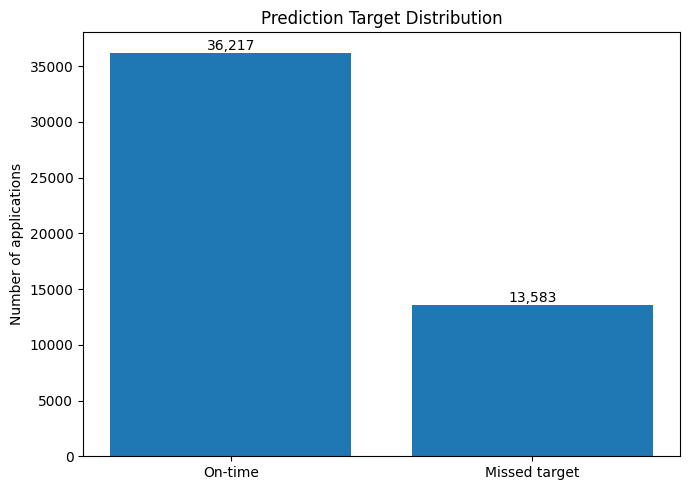

In [14]:

print("=" * 80)
print("QUESTION 9 — VISUALIZATIONS")
print("=" * 80)

VIZ_DIR = OUTPUT_DIR / "visualizations"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(VIZ_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

# 1. Target distribution
counts = df["missed_target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 5))
values = [counts.get(0, 0), counts.get(1, 0)]
ax.bar(["On-time", "Missed target"], values)
ax.set_title("Prediction Target Distribution")
ax.set_ylabel("Number of applications")
for i, v in enumerate(values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
save_show(fig, "01_target_distribution.png")




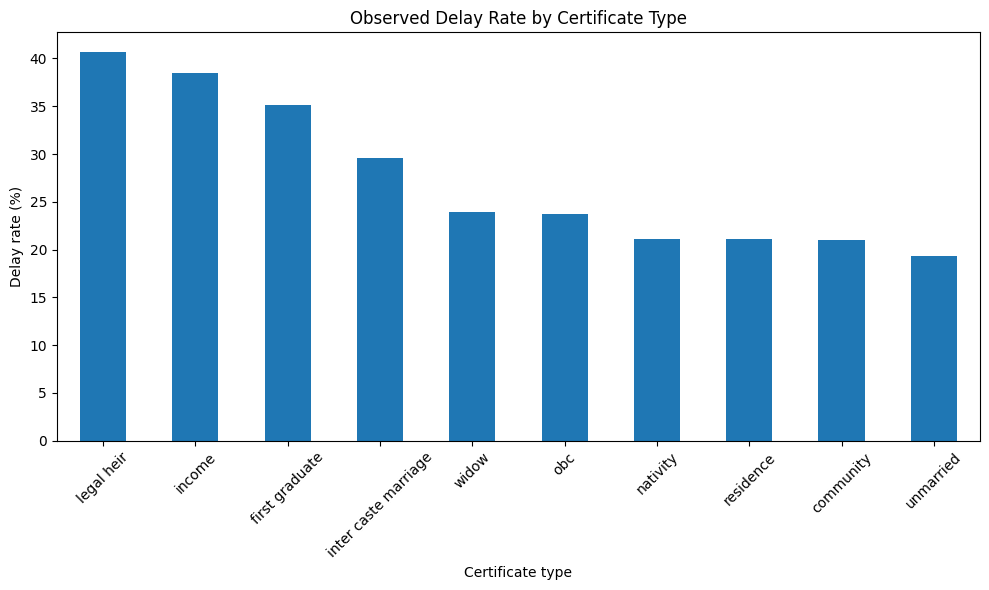

In [15]:
# 2. Delay rate by certificate type
rate = (
    df.groupby("certificate_type")["missed_target"]
      .mean()
      .sort_values(ascending=False) * 100
)
fig, ax = plt.subplots(figsize=(10, 6))
rate.plot(kind="bar", ax=ax)
ax.set_title("Observed Delay Rate by Certificate Type")
ax.set_ylabel("Delay rate (%)")
ax.set_xlabel("Certificate type")
ax.tick_params(axis="x", rotation=45)
save_show(fig, "02_delay_rate_certificate_type.png")


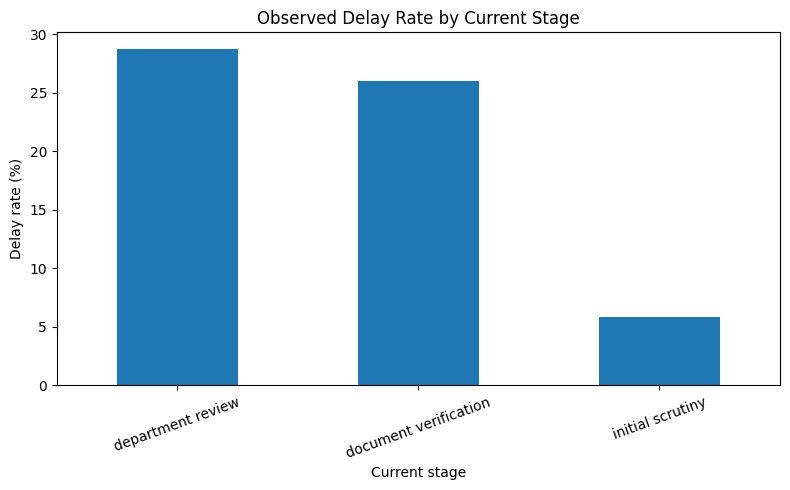

In [16]:
# 3. Delay rate by current stage
rate = (
    df.groupby("current_stage")["missed_target"]
      .mean()
      .sort_values(ascending=False) * 100
)
fig, ax = plt.subplots(figsize=(8, 5))
rate.plot(kind="bar", ax=ax)
ax.set_title("Observed Delay Rate by Current Stage")
ax.set_ylabel("Delay rate (%)")
ax.set_xlabel("Current stage")
ax.tick_params(axis="x", rotation=20)
save_show(fig, "03_delay_rate_current_stage.png")


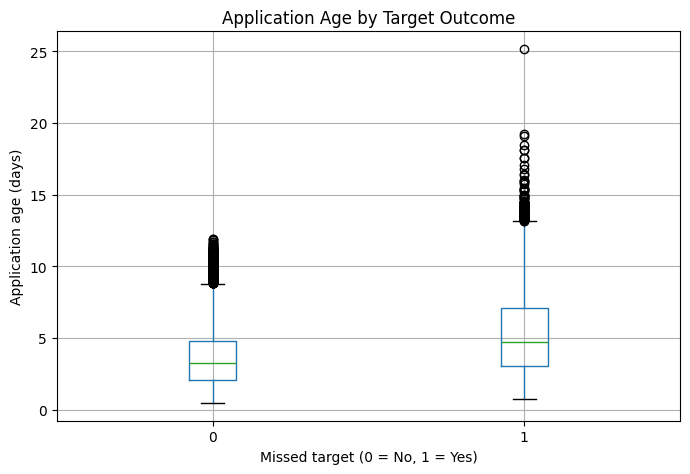

In [17]:
# 4. Application age vs target
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column="application_age_days", by="missed_target", ax=ax)
ax.set_title("Application Age by Target Outcome")
ax.set_xlabel("Missed target (0 = No, 1 = Yes)")
ax.set_ylabel("Application age (days)")
fig.suptitle("")
save_show(fig, "04_application_age_vs_target.png")


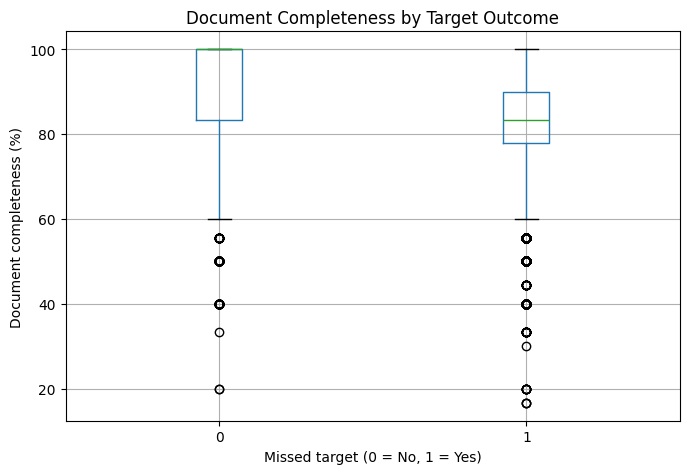

In [18]:
# 5. Document completeness vs target
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column="document_completeness_pct", by="missed_target", ax=ax)
ax.set_title("Document Completeness by Target Outcome")
ax.set_xlabel("Missed target (0 = No, 1 = Yes)")
ax.set_ylabel("Document completeness (%)")
fig.suptitle("")
save_show(fig, "05_document_completeness_vs_target.png")


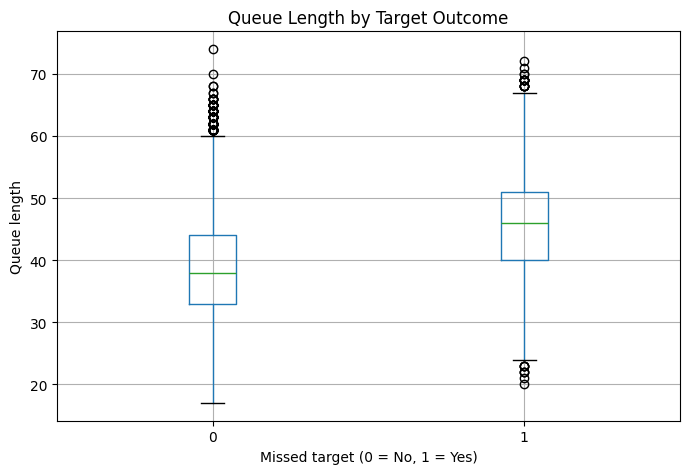

In [19]:
# 6. Queue length vs target
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column="queue_length", by="missed_target", ax=ax)
ax.set_title("Queue Length by Target Outcome")
ax.set_xlabel("Missed target (0 = No, 1 = Yes)")
ax.set_ylabel("Queue length")
fig.suptitle("")
save_show(fig, "06_queue_length_vs_target.png")


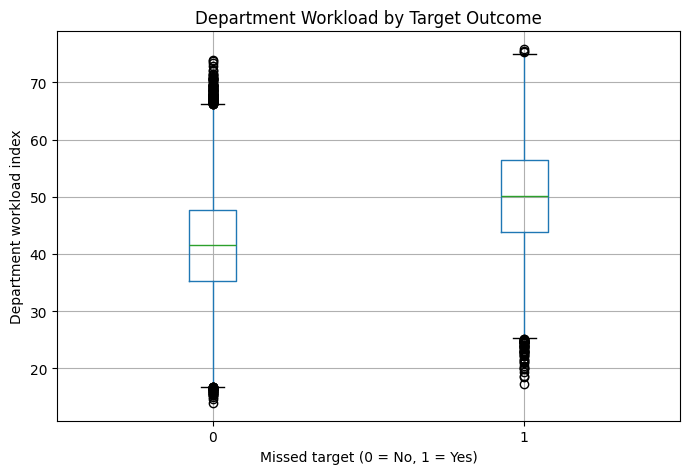

In [20]:
# 7. Department workload vs target
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column="department_workload_index", by="missed_target", ax=ax)
ax.set_title("Department Workload by Target Outcome")
ax.set_xlabel("Missed target (0 = No, 1 = Yes)")
ax.set_ylabel("Department workload index")
fig.suptitle("")
save_show(fig, "07_workload_vs_target.png")


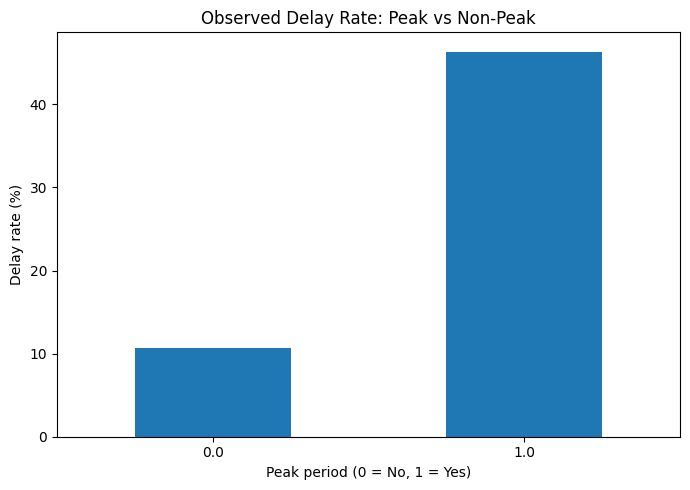

In [21]:
# 8. Peak period vs target
peak_rate = df.groupby("peak_period_flag")["missed_target"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 5))
peak_rate.plot(kind="bar", ax=ax)
ax.set_title("Observed Delay Rate: Peak vs Non-Peak")
ax.set_ylabel("Delay rate (%)")
ax.set_xlabel("Peak period (0 = No, 1 = Yes)")
ax.tick_params(axis="x", rotation=0)
save_show(fig, "08_peak_period_delay_rate.png")


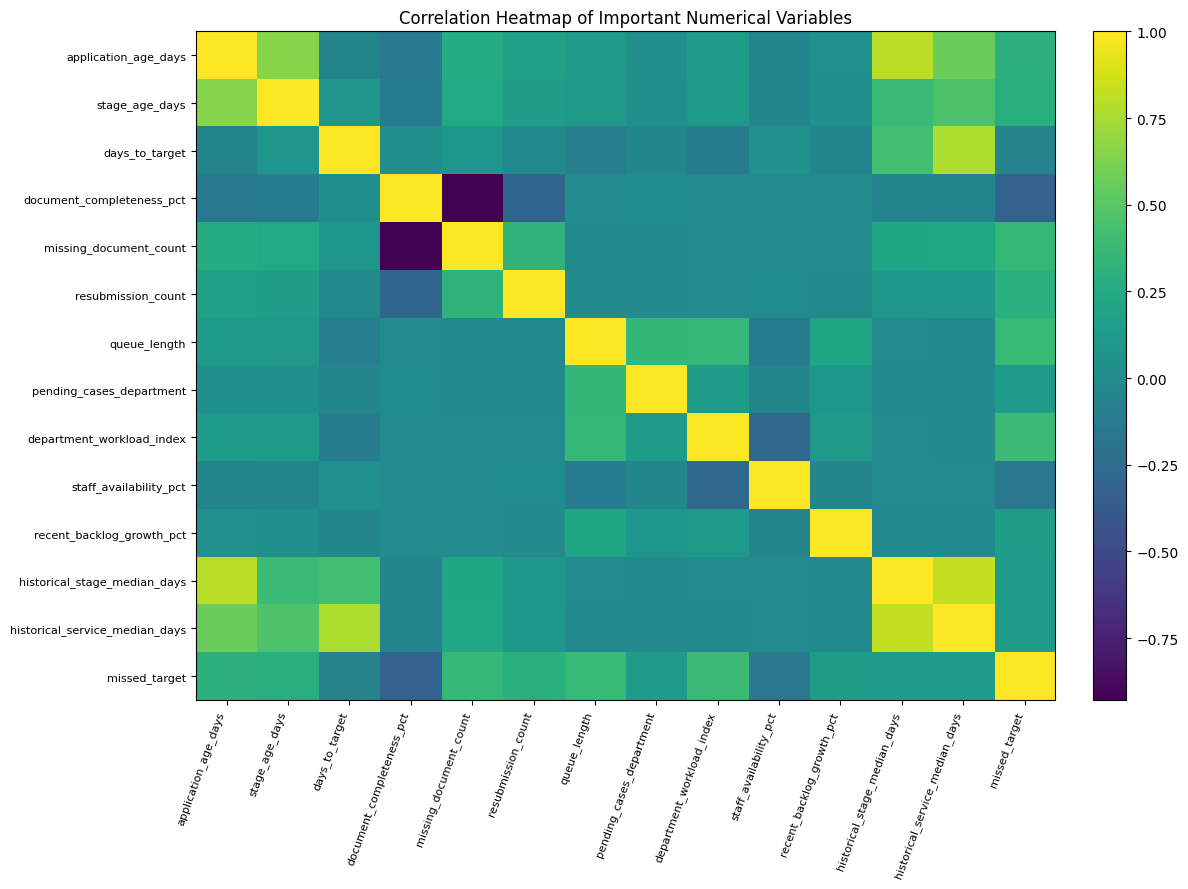

In [22]:
# 9. Correlation heatmap using matplotlib only
corr_cols = [
    "application_age_days", "stage_age_days", "days_to_target",
    "document_completeness_pct", "missing_document_count",
    "resubmission_count", "queue_length", "pending_cases_department",
    "department_workload_index", "staff_availability_pct",
    "recent_backlog_growth_pct", "historical_stage_median_days",
    "historical_service_median_days", "missed_target"
]
corr_cols = [c for c in corr_cols if c in df.columns]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr.values, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=70, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
ax.set_title("Correlation Heatmap of Important Numerical Variables")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
save_show(fig, "09_correlation_heatmap.png")


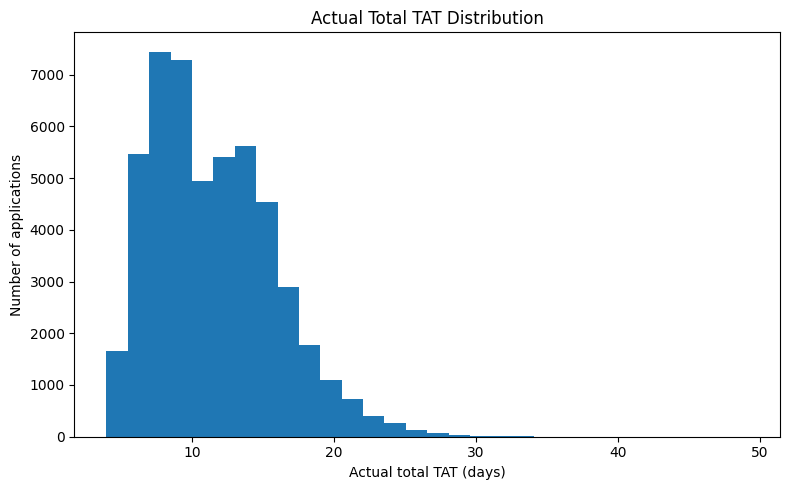


All visualization files saved to: D:\Datascience Hackathon\certificate-delay-intelligence\outputs\round1_notebook\visualizations


In [23]:
# 10. Actual total TAT distribution
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["actual_total_tat_days"].dropna(), bins=30)
ax.set_title("Actual Total TAT Distribution")
ax.set_xlabel("Actual total TAT (days)")
ax.set_ylabel("Number of applications")
save_show(fig, "10_actual_total_tat_distribution.png")

print("\nAll visualization files saved to:", VIZ_DIR)

# Question 10

## Identify the features that are relevant to the prediction target.

In [13]:

print("=" * 80)
print("QUESTION 10 — FEATURE RELEVANCE")
print("=" * 80)

target = df["missed_target"].astype(int)

numeric_features = [
    "submission_month", "peak_period_flag", "application_age_days",
    "stage_age_days", "days_to_target", "target_tat_days",
    "required_document_count", "submitted_document_count",
    "document_completeness_pct", "missing_document_count",
    "verification_complexity", "resubmission_count", "queue_length",
    "pending_cases_department", "department_workload_index",
    "staff_availability_pct", "recent_backlog_growth_pct",
    "historical_stage_median_days", "historical_service_median_days"
]
numeric_features = [c for c in numeric_features if c in df.columns]

rows = []
for col in numeric_features:
    x = pd.to_numeric(df[col], errors="coerce")
    valid = x.notna() & target.notna()

    if valid.sum() == 0 or x[valid].nunique() < 2:
        corr, pval = np.nan, np.nan
    else:
        corr, pval = pointbiserialr(target[valid], x[valid])

    try:
        a = x[target == 0].dropna()
        b = x[target == 1].dropna()
        _, mw_p = mannwhitneyu(a, b, alternative="two-sided")
    except Exception:
        mw_p = np.nan

    rows.append([
        col, "numeric", corr, pval, mw_p,
        abs(corr) if pd.notna(corr) else 0
    ])

relevance = pd.DataFrame(rows, columns=[
    "feature", "type", "point_biserial_r",
    "point_biserial_p", "mann_whitney_p", "absolute_effect"
]).sort_values("absolute_effect", ascending=False)

print("\nNumeric feature relevance:")
display(relevance)

print("\nCategorical feature relevance using Cramér's V:")
cat_features = [
    "service_code", "certificate_type", "district",
    "submission_channel", "current_stage",
    "target_tat_basis", "submission_day_of_week"
]
cat_features = [c for c in cat_features if c in df.columns]

cat_rows = []
for col in cat_features:
    table = pd.crosstab(df[col], target)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    r, k = table.shape
    denom = min(k - 1, r - 1)
    cramers_v = np.sqrt((chi2 / n) / denom) if denom > 0 else np.nan
    cat_rows.append([col, "categorical", cramers_v, p])

cat_relevance = pd.DataFrame(
    cat_rows,
    columns=["feature", "type", "cramers_v", "chi_square_p"]
).sort_values("cramers_v", ascending=False)

display(cat_relevance)

print("\nInitial modeling feature set:")
model_features = numeric_features + [
    "service_code", "certificate_type", "district",
    "target_tat_basis", "current_stage", "submission_day_of_week"
]
model_features = [c for c in model_features if c in df.columns]
print(model_features)

print("""
Excluded from model features:
• application_id — identifier
• actual_* outcome columns — target leakage
• missed_target — classification target itself
• delay_overrun_days — outcome-derived
• actual_bottleneck_stage — outcome-derived
• data_quality_flag — not included in the initial model
• submission_channel — very weak observed relationship
• taluk — high-cardinality feature not included initially
""")

relevance.to_csv(
    OUTPUT_DIR / "round1_numeric_feature_relevance.csv", index=False
)
cat_relevance.to_csv(
    OUTPUT_DIR / "round1_categorical_feature_relevance.csv", index=False
)
pd.DataFrame({"model_feature": model_features}).to_csv(
    OUTPUT_DIR / "round1_model_features.csv", index=False
)

print("Feature reports saved to:", OUTPUT_DIR)


QUESTION 10 — FEATURE RELEVANCE

Numeric feature relevance:


,feature,type,point_biserial_r,point_biserial_p,mann_whitney_p,absolute_effect
1,peak_period_flag,numeric,0.399238,0.000000e+00,0.000000e+00,0.399238
14,department_workload_index,numeric,0.385298,0.000000e+00,0.000000e+00,0.385298
12,queue_length,numeric,0.373329,0.000000e+00,0.000000e+00,0.373329
9,missing_document_count,numeric,0.359134,0.000000e+00,0.000000e+00,0.359134
8,document_completeness_pct,numeric,-0.320086,0.000000e+00,0.000000e+00,0.320086
2,application_age_days,numeric,0.309724,0.000000e+00,0.000000e+00,0.309724
11,resubmission_count,numeric,0.298155,0.000000e+00,0.000000e+00,0.298155
3,stage_age_days,numeric,0.278230,0.000000e+00,0.000000e+00,0.278230
0,submission_month,numeric,0.207521,0.000000e+00,0.000000e+00,0.207521
10,verification_complexity,numeric,0.168593,3.285046e-314,2.875158e-290,0.168593



Categorical feature relevance using Cramér's V:


,feature,type,cramers_v,chi_square_p
0,service_code,categorical,0.177166,0.000000e+00
1,certificate_type,categorical,0.177166,0.000000e+00
2,district,categorical,0.099863,8.439452e-82
5,target_tat_basis,categorical,0.090901,4.410171e-90
4,current_stage,categorical,0.048768,1.909788e-26
6,submission_day_of_week,categorical,0.016945,2.646891e-02
3,submission_channel,categorical,0.003207,4.742048e-01



Initial modeling feature set:
['submission_month', 'peak_period_flag', 'application_age_days', 'stage_age_days', 'days_to_target', 'target_tat_days', 'required_document_count', 'submitted_document_count', 'document_completeness_pct', 'missing_document_count', 'verification_complexity', 'resubmission_count', 'queue_length', 'pending_cases_department', 'department_workload_index', 'staff_availability_pct', 'recent_backlog_growth_pct', 'historical_stage_median_days', 'historical_service_median_days', 'service_code', 'certificate_type', 'district', 'target_tat_basis', 'current_stage', 'submission_day_of_week']

Excluded from model features:
• application_id — identifier
• actual_* outcome columns — target leakage
• missed_target — classification target itself
• delay_overrun_days — outcome-derived
• actual_bottleneck_stage — outcome-derived
• data_quality_flag — not included in the initial model
• submission_channel — very weak observed relationship
• taluk — high-cardinality feature not 

# Round 1 Final Checklist

After running all cells, the notebook explicitly covers all 10 mandatory Round 1 questions:

1. Objective and prediction target
2. Dataset import and inspection
3. Dimensions, attributes, data types and target distribution
4. Missing values, duplicates, inconsistent values and incorrect data types
5. Noise and outliers using IQR
6. Categorical encoding using One-Hot Encoding
7. Descriptive statistics
8. EDA and important relationships
9. Required visualizations
10. Feature relevance

**Next:** Round 2 — leakage-safe preprocessing, Random Forest classification, Random Forest regression, bottleneck analysis and application prioritization.